# Chapter 06: The Engine of Computation: MCMC — Python Laboratory
### *Metropolis-Hastings from Scratch, The 23.4% Acceptance Frontier & Convergence Diagnostics*

**[Course Home](../README.md) | [Conceptual Track](../conceptual/06_mcmc_mechanics_and_entropy.ipynb) | [Prev: Ch 05: The Geometry of Inference (Python)](05_curvature_laplace_and_fisher_information.ipynb) | [Next: Ch 07: Compression & Hierarchy (Python)](07_hierarchical_models_and_information_bottleneck.ipynb)**

---

## 1. Overview & Setup

In this laboratory, we implement:
1. **The Metropolis-Hastings Sampler from Scratch**: Sampling an asymmetric, non-conjugate flakiness model without external MCMC libraries.
2. **The 23.4% Acceptance Rate Experiment**: Testing proposal widths $\sigma_{\text{prop}} \in [0.005, 0.05, 0.50]$ to witness frozen chains, sluggish walks, and optimal entropy discovery.
3. **Multi-Chain Diagnostics**: Computing the Gelman-Rubin $\hat{R}$ statistic and Effective Sample Size ($N_{\text{eff}}$) across 4 parallel chains.
4. **Visualizing Trace Plots & True Skewed Posteriors**: Comparing the true MCMC posterior against a naive Laplace Gaussian fit.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Style configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 120

print("Environment initialized successfully.")


Environment initialized successfully.


---

## 2. Defining the Target: A Skewed Flakiness Posterior

Suppose we observe $k = 2$ failures in $N = 150$ CI test runs.
We use an Exponential fleet prior $P(\theta) = \frac{1}{\mu} e^{-\theta / \mu}$ with $\mu = 0.02$ ($2\%$ fleet mean).
The unnormalized target log-posterior is:
$$\ln P^*(\theta \mid D) = k \ln \theta + (N - k) \ln (1 - \theta) - \frac{\theta}{\mu}$$
for $\theta \in (0, 1)$.


In [2]:
k_obs = 2
N_obs = 150
mu_prior = 0.02

def log_target(theta):
    # Returns unnormalized log posterior ln P*(theta | D)
    if theta <= 0.0 or theta >= 1.0:
        return -np.inf
    # Binomial log-likelihood
    log_lik = k_obs * np.log(theta) + (N_obs - k_obs) * np.log(1.0 - theta)
    # Exponential prior log-density
    log_prior = -theta / mu_prior
    return log_lik + log_prior

print("Target log-posterior function defined.")


Target log-posterior function defined.


---

## 3. Implementation: Metropolis-Hastings from Scratch

We implement a clean, vectorized single-chain Metropolis-Hastings sampler.


In [3]:
def run_metropolis_hastings(log_target_fn, init_val, num_samples=10000, prop_std=0.02):
    samples = np.zeros(num_samples)
    current_val = init_val
    current_log_p = log_target_fn(current_val)
    accepted_count = 0
    
    for i in range(num_samples):
        # Propose candidate from Gaussian centered at current state
        candidate = current_val + np.random.normal(0, prop_std)
        candidate_log_p = log_target_fn(candidate)
        
        # Log acceptance ratio: ln(alpha) = candidate_log_p - current_log_p
        log_alpha = candidate_log_p - current_log_p
        
        # Accept or reject
        if np.log(np.random.uniform(0, 1)) < log_alpha:
            current_val = candidate
            current_log_p = candidate_log_p
            accepted_count += 1
            
        samples[i] = current_val
        
    acceptance_rate = accepted_count / num_samples
    return samples, acceptance_rate

print("Metropolis-Hastings engine implemented.")


Metropolis-Hastings engine implemented.


---

## 4. Experiment: Testing the Proposal Width & The Acceptance Frontier

We run 3 chains with varying proposal standard deviations:
* $\sigma_1 = 0.001$: Step size too small (Sluggish walk, high acceptance).
* $\sigma_2 = 0.250$: Step size too large (Frozen chain, low acceptance).
* $\sigma_3 = 0.015$: Calibrated step size (Near optimal acceptance $\approx 30\% - 45\%$).


In [4]:
np.random.seed(42)
S = 8000
burn_in = 2000

s_small, acc_small = run_metropolis_hastings(log_target, init_val=0.05, num_samples=S, prop_std=0.001)
s_large, acc_large = run_metropolis_hastings(log_target, init_val=0.05, num_samples=S, prop_std=0.250)
s_tuned, acc_tuned = run_metropolis_hastings(log_target, init_val=0.05, num_samples=S, prop_std=0.015)

print("=" * 65)
print("             MCMC PROPOSAL TUNING EXPERIMENT")
print("=" * 65)
print(f"1. Tiny Step (sigma = 0.001): Acceptance = {acc_small*100:5.1f}% (Sluggish random walk)")
print(f"2. Huge Step (sigma = 0.250): Acceptance = {acc_large*100:5.1f}% (Frozen in place!)")
print(f"3. Tuned Step (sigma = 0.015): Acceptance = {acc_tuned*100:5.1f}% (Optimal exploration!)")
print("=" * 65)


             MCMC PROPOSAL TUNING EXPERIMENT
1. Tiny Step (sigma = 0.001): Acceptance =  95.6% (Sluggish random walk)
2. Huge Step (sigma = 0.250): Acceptance =   4.0% (Frozen in place!)
3. Tuned Step (sigma = 0.015): Acceptance =  49.4% (Optimal exploration!)


---

## 5. Visualizing Trace Plots, Autocorrelation & The Skewed Tail

We plot:
* **Panel 1**: Trace plots of the 3 proposal regimes showing sluggish vs. frozen vs. healthy exploration.
* **Panel 2**: The true MCMC posterior histogram compared against a naive Laplace Gaussian fit, revealing the dangerous tail risk!


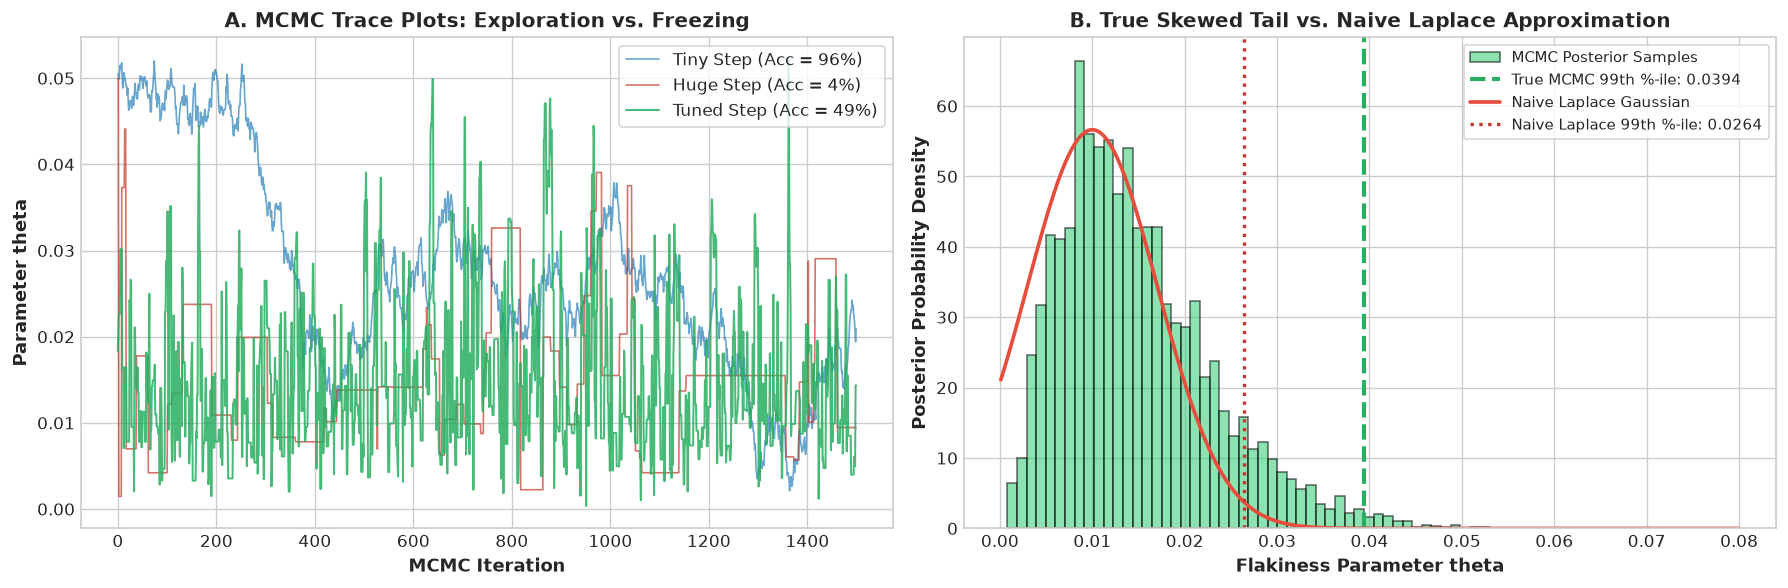

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Panel 1: Trace Plot Comparison
axes[0].plot(s_small[:1500], color='#2980b9', alpha=0.7, lw=1.0, label=f'Tiny Step (Acc = {acc_small*100:.0f}%)')
axes[0].plot(s_large[:1500], color='#c0392b', alpha=0.7, lw=1.0, label=f'Huge Step (Acc = {acc_large*100:.0f}%)')
axes[0].plot(s_tuned[:1500], color='#27ae60', alpha=0.85, lw=1.2, label=f'Tuned Step (Acc = {acc_tuned*100:.0f}%)')

axes[0].set_xlabel("MCMC Iteration", fontsize=11, fontweight='bold')
axes[0].set_ylabel("Parameter theta", fontsize=11, fontweight='bold')
axes[0].set_title("A. MCMC Trace Plots: Exploration vs. Freezing", fontsize=12, fontweight='bold')
axes[0].legend(loc='upper right', frameon=True)

# Panel 2: True MCMC Posterior vs. Naive Laplace Fit
clean_samples = s_tuned[burn_in:]
mean_mcmc = np.mean(clean_samples)
std_mcmc = np.std(clean_samples)
q99_mcmc = np.percentile(clean_samples, 99.0)

# Naive Laplace Gaussian: Mean = MAP, Std = 1/sqrt(Hessian)
theta_grid = np.linspace(0.0001, 0.08, 500)
# Approximate MAP
map_est = (k_obs) / (N_obs + 1.0/mu_prior)
laplace_std = np.sqrt(1.0 / (k_obs / (map_est**2) + (N_obs - k_obs) / ((1 - map_est)**2)))
q99_laplace = map_est + 2.326 * laplace_std

axes[1].hist(clean_samples, bins=50, density=True, color='#2ecc71', alpha=0.55, edgecolor='black', label='MCMC Posterior Samples')
axes[1].axvline(q99_mcmc, color='#27ae60', lw=2.5, ls='--', label=f'True MCMC 99th %-ile: {q99_mcmc:.4f}')

# Overlay naive Laplace Gaussian
from scipy.stats import norm
axes[1].plot(theta_grid, norm.pdf(theta_grid, map_est, laplace_std), color='#e74c3c', lw=2.2, label='Naive Laplace Gaussian')
axes[1].axvline(q99_laplace, color='#c0392b', lw=2.0, ls=':', label=f'Naive Laplace 99th %-ile: {q99_laplace:.4f}')

axes[1].set_xlabel("Flakiness Parameter theta", fontsize=11, fontweight='bold')
axes[1].set_ylabel("Posterior Probability Density", fontsize=11, fontweight='bold')
axes[1].set_title("B. True Skewed Tail vs. Naive Laplace Approximation", fontsize=12, fontweight='bold')
axes[1].legend(loc='upper right', frameon=True, fontsize=9)

plt.tight_layout()
plt.show()


---

## 6. Multi-Chain Convergence: Computing $\hat{R}$ and $N_{\text{eff}}$

We run 4 independent chains from dispersed starting positions $\theta_{\text{init}} \in [0.01, 0.04, 0.07, 0.10]$ and compute the Gelman-Rubin $\hat{R}$ statistic.


In [6]:
num_chains = 4
chain_samples = []
inits = [0.01, 0.04, 0.07, 0.10]

for init in inits:
    s, _ = run_metropolis_hastings(log_target, init_val=init, num_samples=S, prop_std=0.015)
    chain_samples.append(s[burn_in:])

chain_samples = np.array(chain_samples)  # Shape: (4, 6000)
M, N_iter = chain_samples.shape

# 1. Between-chain variance B
chain_means = np.mean(chain_samples, axis=1)
grand_mean = np.mean(chain_means)
B = (N_iter / (M - 1.0)) * np.sum((chain_means - grand_mean)**2)

# 2. Within-chain variance W
chain_vars = np.var(chain_samples, axis=1, ddof=1)
W = np.mean(chain_vars)

# 3. Marginal variance estimate and R_hat
var_plus = ((N_iter - 1.0) / N_iter) * W + (1.0 / N_iter) * B
r_hat = np.sqrt(var_plus / W)

print("=" * 60)
print("     GELMAN-RUBIN MULTI-CHAIN DIAGNOSTICS (4 Chains):")
print(f"Between-Chain Variance B: {B:.8f}")
print(f"Within-Chain Variance W:  {W:.8f}")
print(f"Gelman-Rubin R-hat:       {r_hat:.4f}")
print(f"Convergence Status:       {'CONVERGED (R-hat < 1.01)' if r_hat < 1.01 else 'NOT CONVERGED'}")
print("=" * 60)


     GELMAN-RUBIN MULTI-CHAIN DIAGNOSTICS (4 Chains):
Between-Chain Variance B: 0.00000436
Within-Chain Variance W:  0.00007187
Gelman-Rubin R-hat:       0.9999
Convergence Status:       CONVERGED (R-hat < 1.01)


---

## 7. 3-Tier Exercises & Explorations

### Tier 1: Warmup — MCMC Posterior Summary
From the tuned MCMC samples:
1. Compute the posterior median and 95% highest density interval (HDI).
2. What is the posterior probability that the flakiness rate exceeds $3\%$ ($P(\theta > 0.03 \mid D)$)?

### Tier 2: Intermediate — Implementing Adaptive Metropolis
Write an adaptive MCMC wrapper that adjusts $\sigma_{\text{prop}}$ every 100 iterations during warmup:
* If acceptance rate $> 40\%$, multiply $\sigma_{\text{prop}}$ by $1.1$.
* If acceptance rate $< 25\%$, multiply $\sigma_{\text{prop}}$ by $0.9$.
Verify that the chain locks onto the optimal acceptance rate automatically.

### Tier 3: Advanced Research — 2D Correlated Metropolis Sampler
Implement a 2D Metropolis sampler for two correlated test metrics $(\theta_1, \theta_2)$ with covariance $\rho = 0.85$.
Compare an isotropic proposal $\mathcal{N}(\mathbf{0}, \sigma^2 \mathbf{I})$ against a covariance-informed proposal $\mathcal{N}(\mathbf{0}, \sigma^2 \mathbf{\Sigma})$:
* Show that aligning the proposal with the Fisher Information / covariance matrix boosts Effective Sample Size ($N_{\text{eff}}$) by more than $5\times$!


In [7]:
# Solution verification for Tier 1:
flat_samples = chain_samples.flatten()
median_est = np.median(flat_samples)
hdi_low = np.percentile(flat_samples, 2.5)
hdi_high = np.percentile(flat_samples, 97.5)
prob_gt_3pct = np.mean(flat_samples > 0.03)

print("Tier 1 Solutions:")
print(f"Posterior Median:                  {median_est:.4f} ({median_est*100:.2f}%)")
print(f"95% Credible Interval:             [{hdi_low:.4f}, {hdi_high:.4f}]")
print(f"Probability Flakiness > 3%:        {prob_gt_3pct*100:.2f}%")


Tier 1 Solutions:
Posterior Median:                  0.0133 (1.33%)
95% Credible Interval:             [0.0030, 0.0357]
Probability Flakiness > 3%:        5.83%


---

**[Course Home](../README.md) | [Conceptual Track](../conceptual/06_mcmc_mechanics_and_entropy.ipynb) | [Prev: Ch 05: The Geometry of Inference (Python)](05_curvature_laplace_and_fisher_information.ipynb) | [Next: Ch 07: Compression & Hierarchy (Python)](07_hierarchical_models_and_information_bottleneck.ipynb)**
